In [7]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import community
from itertools import combinations

In [8]:
# Load Datasets
def load_images(class_folder, img_size=(64, 64)):
    X = []

    for file in os.listdir(class_folder):
        img_path = os.path.join(class_folder, file)

        # Read image (BGR)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files

        # Resize -> not necessary for ORB/SIFT but more robust+faster processing
        #img = cv2.resize(img, img_size) # Resizing led to worse quality images with fewer keypoints

        X.append(img)

    return X

In [9]:
X_train = load_images("Datasets/dataset_1/group_5-15")

### Phase 1: Grouping images into regions

In [10]:
# Extract local features from every image - ORB

features = []
orb = cv2.ORB_create(nfeatures=2000)
# increasing number of matches from 500(default) to 1000 to 1500 to 2000 to 2500 increased final matches from 31 to 34 to 41 to 47 to 54 -> little effect

for img in X_train:

    kp, des = orb.detectAndCompute(img, None)
    if des is None:
        print(f"Warning: No descriptors found for image index {len(features)}")
    features.append((kp, des))

    SHOW_KEYPOINTS = False  # True -> if you want to display keypoints extracted

    if SHOW_KEYPOINTS:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Convert img from BGR to RGB
        img2 = cv2.drawKeypoints(img_rgb, kp, None, color=(255,0,255), flags=0)
        plt.imshow(img2), plt.show()

In [11]:
def compute_overlap_ratio(H, img_shape):
    h, w = img_shape[:2]
    corners = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
    projected = cv2.perspectiveTransform(corners, H)
    
    # Compute intersection area with original image bounds
    rect1 = (0, 0, w, h)
    x,y,w2,h2 = cv2.boundingRect(projected.astype(np.int32))
    
    # Intersection
    ix = max(0, min(rect1[2], x+w2) - max(rect1[0], x))
    iy = max(0, min(rect1[3], y+h2) - max(rect1[1], y))
    intersection = ix * iy
    union = w*h + w2*h2 - intersection
    
    return intersection / (w * h)  # what fraction of img1 is covered

In [12]:
# Match features between all image pairs 
# + BFMatcher using Hamming distance 
# + Lowe's ratio test to remove false/ambigious matches 
# + RANSAC for geometric verification
# + Build a similarity graph

def build_similarity_graph(features, ratio_threshold=0.7, min_inliers=100):
    G = nx.Graph()
    n_images = len(features)

    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

    total_matches = 0
    for i, j in combinations(range(len(X_train)), 2):
        img1, (kp1, des1) = X_train[i], features[i]
        img2, (kp2, des2) = X_train[j], features[j]
        
        # Skip if one image has no descriptors
        if des1 is None or des2 is None:
            continue

        # Use knnMatch to find the two best matches for each descriptor
        matches = bf.knnMatch(des1, des2, k=2)  # k=2 to get the two best matches

        # Apply Lowe's Ratio Test to filter out ambiguous matches
        filtered_matches = []
        for m, n in matches:
            if m.distance < ratio_threshold * n.distance:  # Lowe's ratio test
                filtered_matches.append(m)

        if len(filtered_matches) < 4: # Min 4 points needed for homography
            continue

        # Geometric Verification using RANSAC
        src_pts = np.float32([kp1[m.queryIdx].pt for m in filtered_matches]).reshape(-1,1,2)
        dest_pts = np.float32([kp2[m.trainIdx].pt for m in filtered_matches]).reshape(-1,1,2)

        H, mask = cv2.findHomography(src_pts, dest_pts, cv2.RANSAC, ransacReprojThreshold=3.0)

        if H is None:
            continue

        inliers = int(mask.sum()) # number of geometrically consistent matches

        # Build Graph Edge if enough matches
        overlap = compute_overlap_ratio(H, X_train[i].shape)
        if inliers >= min_inliers and overlap > 0.1:  # at least 10% overlap
            G.add_edge(i, j, weight=inliers, overlap=overlap, H=H)
        
        total_matches += inliers
    
    print("Total matches: ",total_matches)
    print("Number of edges (similar pairs):", G.number_of_edges())

    return G

Total matches:  5835
Number of edges (similar pairs): 15


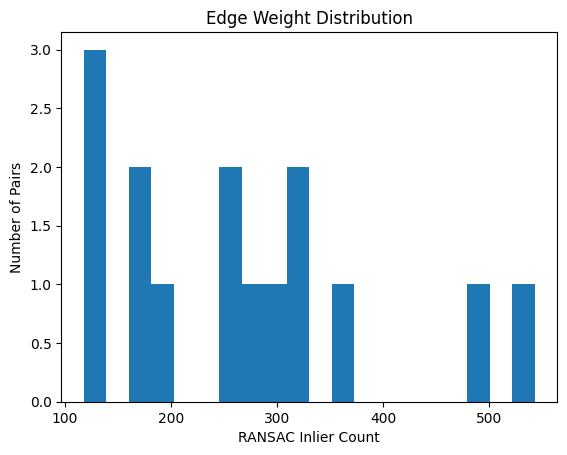

Min: 118, Max: 543, Mean: 266.1


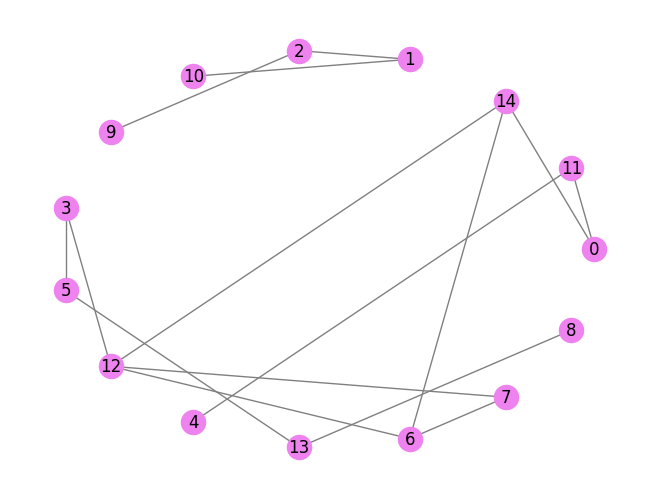

In [13]:
graph = build_similarity_graph(features)

# Display edge weight distribution
weights = [d['weight'] for u, v, d in graph.edges(data=True)]
plt.hist(weights, bins=20)
plt.xlabel("RANSAC Inlier Count")
plt.ylabel("Number of Pairs")
plt.title("Edge Weight Distribution")
plt.show()

print(f"Min: {min(weights)}, Max: {max(weights)}, Mean: {np.mean(weights):.1f}")

# Display simililarity graph (NetworkX)
nx.draw(graph,
        pos=nx.circular_layout(graph),
        with_labels=True,
        node_color='violet', 
        edge_color='gray')
plt.show()

In [14]:
# Louvain-style community detection (greedy modularity) -> performs better than component detection 
communities = community.greedy_modularity_communities(graph, weight='weight')
for idx, comp in enumerate(communities):
    print(f"Group {idx}: images {sorted(comp)}")

Group 0: images [3, 6, 7, 12, 14]
Group 1: images [1, 2, 9, 10]
Group 2: images [0, 4, 11]
Group 3: images [5, 8, 13]


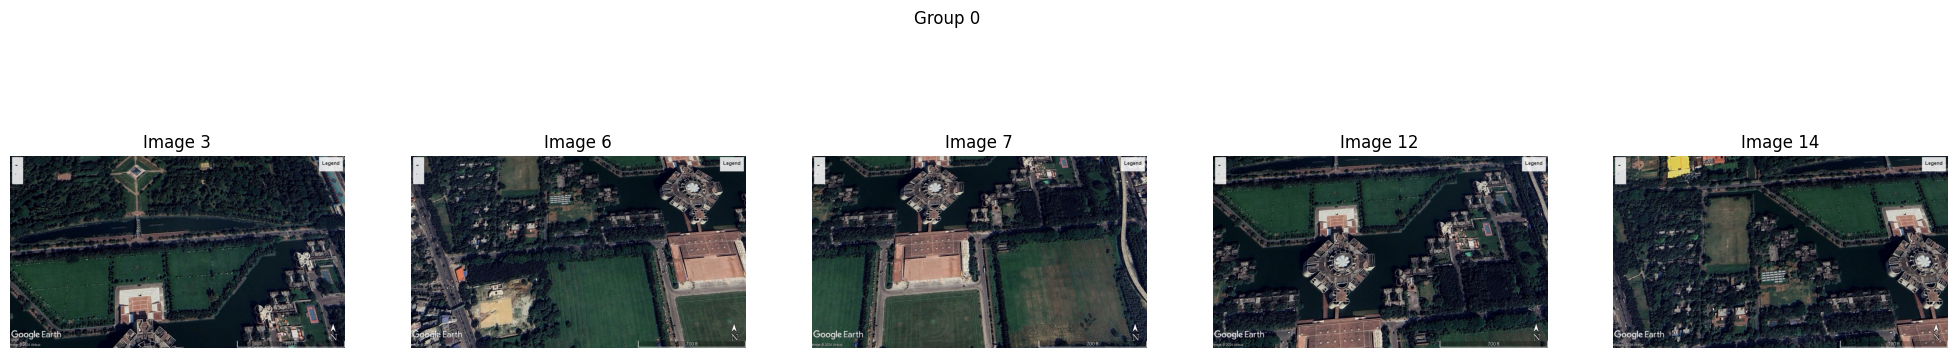

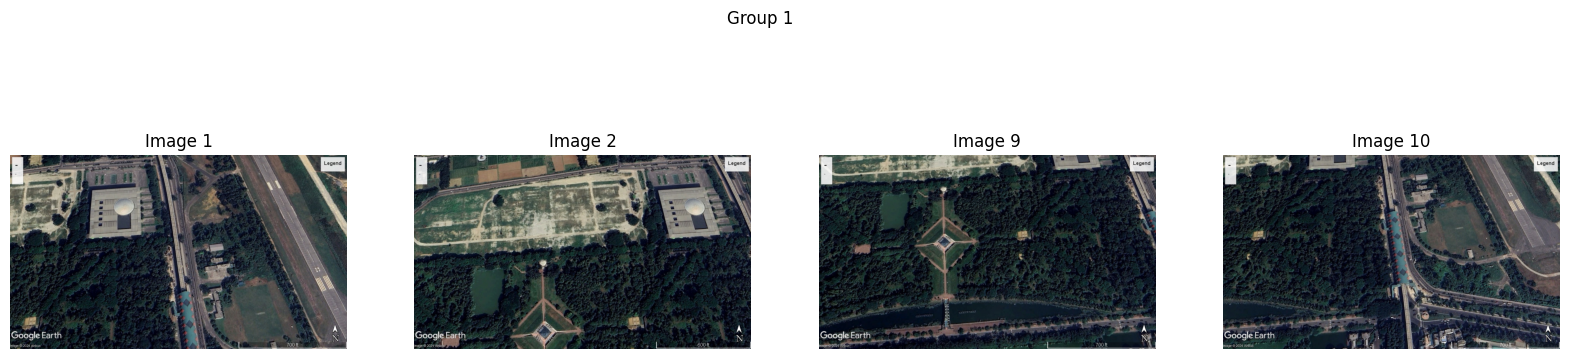

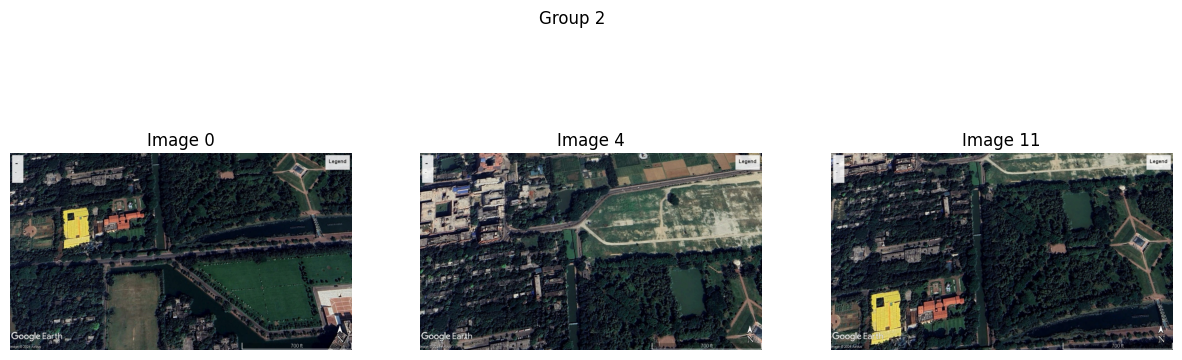

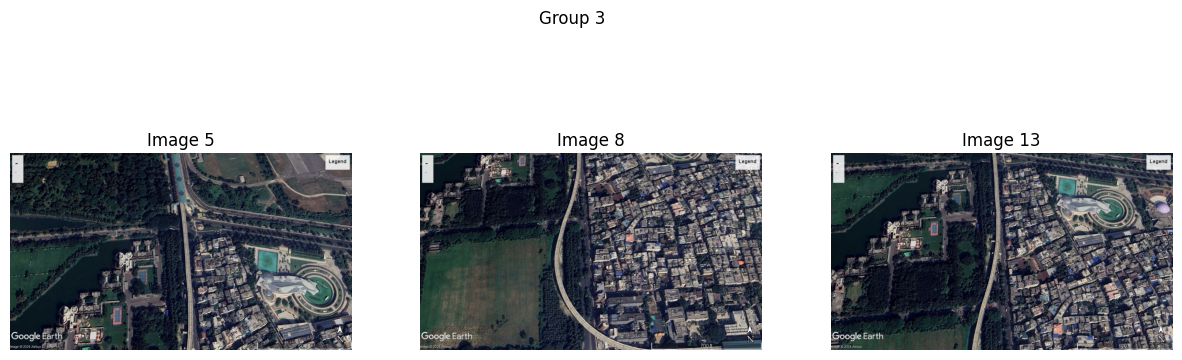

In [15]:
# Visualization of Community images
for group_idx, comp in enumerate(communities):
    images_in_group = sorted(comp)
    n = len(images_in_group)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1:
        axes = [axes]
    for ax, img_idx in zip(axes, images_in_group):
        ax.imshow(cv2.cvtColor(X_train[img_idx], cv2.COLOR_BGR2RGB))
        ax.set_title(f"Image {img_idx}")
        ax.axis('off')
    plt.suptitle(f"Group {group_idx}")
    plt.show()

### Phase 2: Image Stitching

In [16]:
# Decide order for stitching on the basis of Minimum Spanning Tree (MST)

stitching_order = [None] * len(communities)
bfs_trees = [None] * len(communities)
reference_nodes = [None] * len(communities)

for group_idx, comp in enumerate(communities):
    nodes = sorted(comp)
    subgraph = graph.subgraph(nodes)
    
    mst = nx.maximum_spanning_tree(subgraph, weight='weight')
    
    # Pick the node with highest degree in MST as reference (most central or has most connecting edges)
    reference = max(mst.nodes(), key=lambda n: mst.degree(n))
    reference_nodes[group_idx] = reference
    print(f"Group {group_idx}: nodes={nodes}, reference image={reference}")
    
    # BFS order from reference = stitching order
    bfs_trees[group_idx] = nx.bfs_tree(mst, reference)
    stitching_order[group_idx] = list(bfs_trees[group_idx].nodes())
    print(f"  Stitching order: {stitching_order[group_idx]}")
    print(bfs_trees[group_idx])
    print()

Group 0: nodes=[3, 6, 7, 12, 14], reference image=6
  Stitching order: [6, 14, 7, 12, 3]
DiGraph with 5 nodes and 4 edges

Group 1: nodes=[1, 2, 9, 10], reference image=1
  Stitching order: [1, 10, 2, 9]
DiGraph with 4 nodes and 3 edges

Group 2: nodes=[0, 4, 11], reference image=11
  Stitching order: [11, 0, 4]
DiGraph with 3 nodes and 2 edges

Group 3: nodes=[5, 8, 13], reference image=13
  Stitching order: [13, 5, 8]
DiGraph with 3 nodes and 2 edges



In [17]:
# Debugging cells
for node in [14, 7, 12, 3]:
    print(f"6↔{node}: has_edge(6,{node})={graph.has_edge(6,node)}, has_edge({node},6)={graph.has_edge(node,6)}")
    
for group_idx in range(0,4):
    print(f"\nGroup {group_idx} edge weights:")
    for node in bfs_trees[group_idx].nodes():
        if node == reference_nodes[group_idx]:
            continue
        prev = next(bfs_trees[group_idx].predecessors(node))
        if graph.has_edge(prev, node):
            w = graph[prev][node]['weight']
        else:
            w = graph[node][prev]['weight']
        print(f"  {prev} → {node}: {w} inliers")

6↔14: has_edge(6,14)=True, has_edge(14,6)=True
6↔7: has_edge(6,7)=True, has_edge(7,6)=True
6↔12: has_edge(6,12)=True, has_edge(12,6)=True
6↔3: has_edge(6,3)=False, has_edge(3,6)=False

Group 0 edge weights:
  6 → 14: 481 inliers
  6 → 7: 198 inliers
  7 → 12: 543 inliers
  12 → 3: 292 inliers

Group 1 edge weights:
  1 → 10: 272 inliers
  1 → 2: 168 inliers
  2 → 9: 313 inliers

Group 2 edge weights:
  11 → 0: 367 inliers
  11 → 4: 249 inliers

Group 3 edge weights:
  13 → 5: 313 inliers
  13 → 8: 250 inliers


In [ ]:
# Warp image 2 onto canvas
def warp_and_blend(img, H, T_cumulative, canvas_size):
    result = cv2.warpPerspective(img, T_cumulative@H, canvas_size)
    return result

In [ ]:
# Global canvas pre-computation
def calculate_canvas_size(nodes, H_cumulative):

    x_min_global, y_min_global = 0, 0
    x_max_global, y_max_global = 0, 0

    for node in nodes:
        h1, w1 = X_train[node].shape[:2]
        corners = np.float32([[0,0],[w1,0],[w1,h1],[0,h1]]).reshape(-1,1,2)
        warped_corners = cv2.perspectiveTransform(corners, H_cumulative[node])

        x_min, y_min = warped_corners[:,:,0].min(), warped_corners[:,:,1].min()
        x_max, y_max = warped_corners[:,:,0].max(), warped_corners[:,:,1].max()

        x_min_global = min(x_min_global, x_min)
        y_min_global = min(y_min_global, y_min)
        x_max_global = max(x_max_global, x_max)
        y_max_global = max(y_max_global, y_max)

    T_global = np.array([[1, 0, -x_min_global],
                        [0, 1, -y_min_global],
                        [0, 0,  1    ]])
    canvas_size = (int(x_max_global - x_min_global), int(y_max_global - y_min_global))
    return T_global, canvas_size


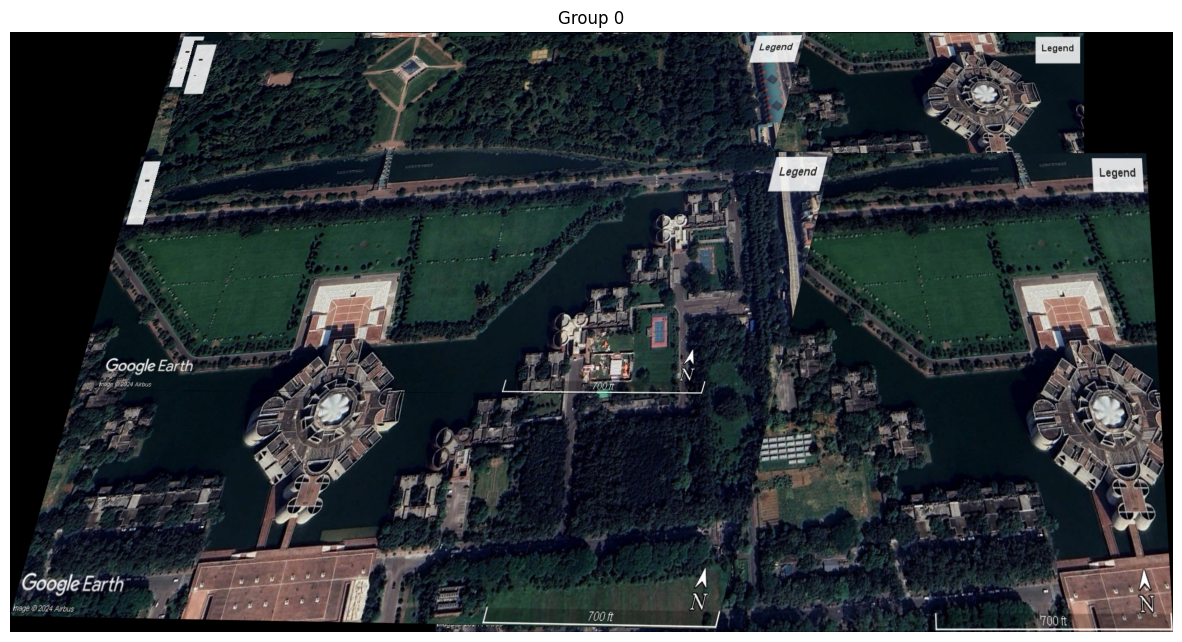

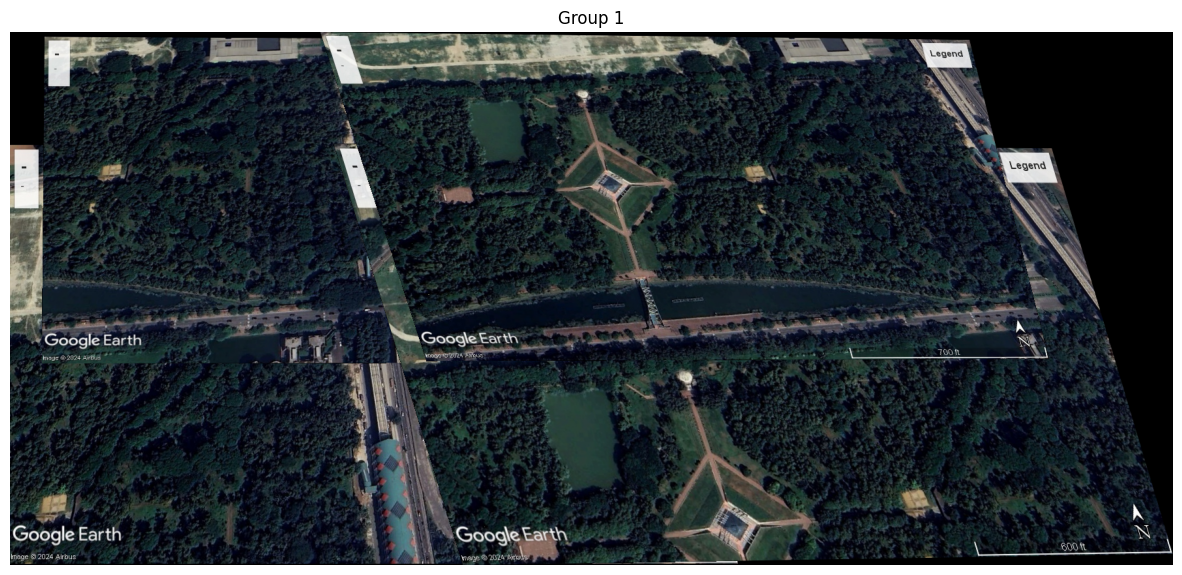

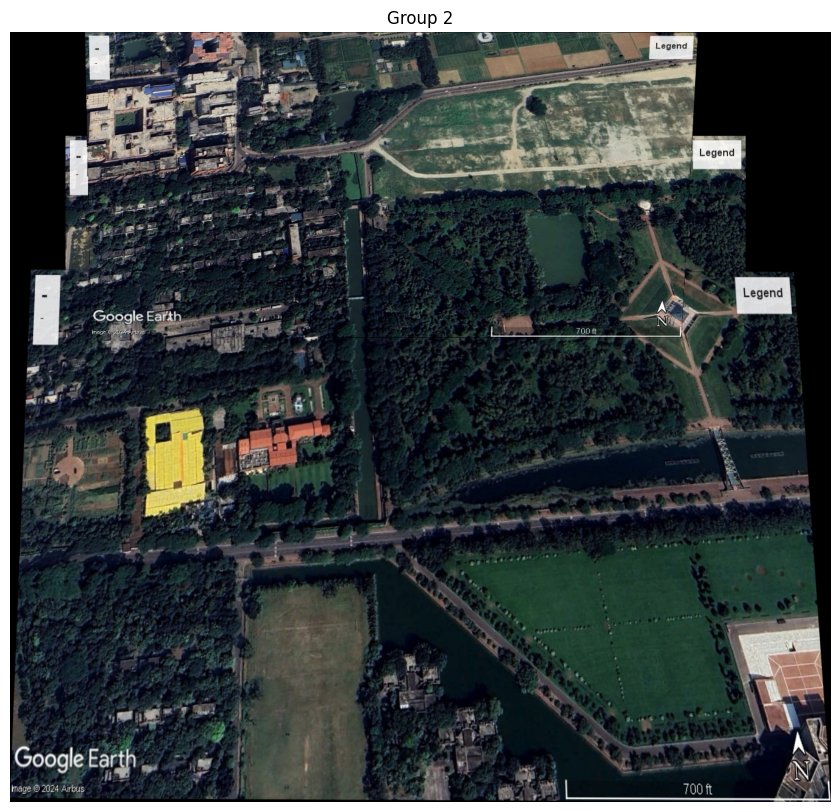

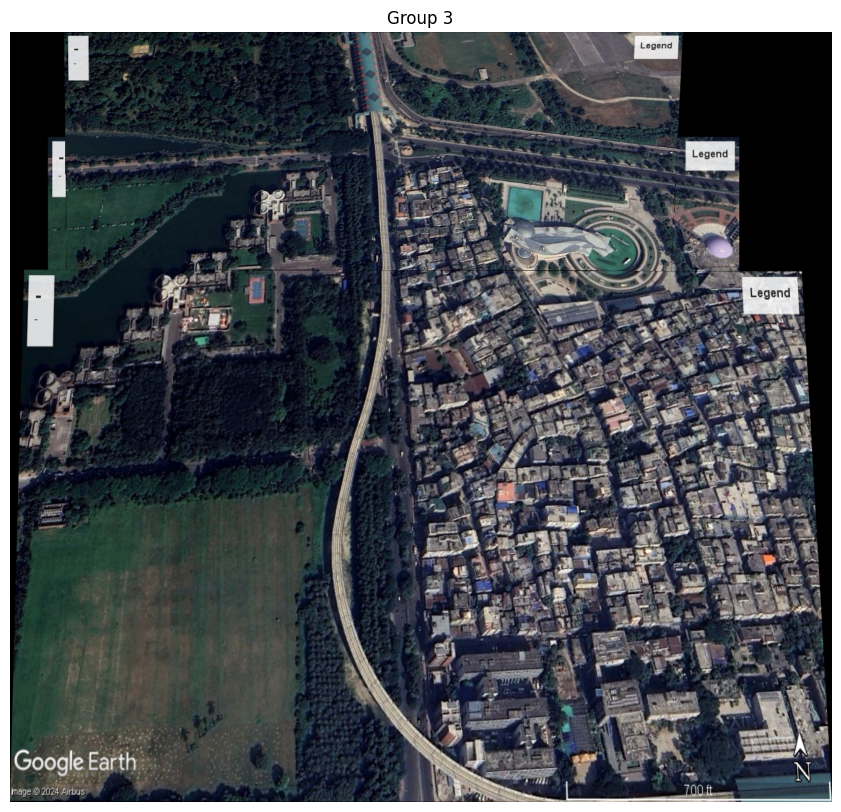

In [ ]:
H_cumulative = {}
T_cumulative = [None] * len(communities)
stitched_maps = [None] * len(communities)
canvas_size = [None] * len(communities)
canvas = [None] * len(communities)

# Calculate cumulative homography per node/image
for group_idx, comp in enumerate(communities): 
    ref_node = reference_nodes[group_idx]
    ref_img = X_train[ref_node]
    for current_node in bfs_trees[group_idx]:
        if current_node == ref_node:
            H_cumulative[ref_node] = np.eye(3)
        else: 
            prev_node = next(bfs_trees[group_idx].predecessors(current_node))
            if graph.has_edge(ref_node, current_node) or graph.has_edge(current_node, ref_node):
                if graph.has_edge(ref_node, current_node):
                    H_pair = graph[ref_node][current_node]['H']
                elif graph.has_edge(current_node, ref_node):
                    H_pair = np.linalg.inv(graph[current_node][ref_node]['H'])
                H_cumulative[current_node] = H_pair
            else:
                if graph.has_edge(prev_node, current_node):
                    H_pair = graph[prev_node][current_node]['H']
                elif graph.has_edge(current_node, prev_node):
                    H_pair = np.linalg.inv(graph[current_node][prev_node]['H'])
                H_cumulative[current_node] = H_cumulative[prev_node] @ H_pair 

# Calculate Cumulative Transformation for each group
for group_idx, comp in enumerate(communities):
            T_cumulative[group_idx], canvas_size[group_idx] = calculate_canvas_size(bfs_trees[group_idx],H_cumulative)
            canvas[group_idx] = np.zeros((canvas_size[group_idx][1], canvas_size[group_idx][0], 3), dtype=np.uint8)

# Warp and blend images region wise
for group_idx, comp in enumerate(communities):
    for current_node in bfs_trees[group_idx]:
            warped = warp_and_blend(X_train[current_node], H_cumulative[current_node], T_cumulative[group_idx], canvas_size[group_idx])
            mask = warped.any(axis=2) 
            canvas[group_idx][mask] = warped[mask]
    stitched_maps[group_idx] = canvas[group_idx]

# Display each stitched region
for group_idx, canvas in enumerate(stitched_maps):
    plt.figure(figsize=(15,10))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.title(f"Group {group_idx}")
    plt.axis('off')
    plt.show()


In [23]:
# Test Cell
img1 = X_train[2]
img2 = X_train[9]

kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

# Use BFMatcher to find matches between descriptors
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)

# Sort matches by distance (best matches first)
matches = sorted(matches, key=lambda x: x.distance)

# Draw top 10 matches
img_matches = cv2.drawMatches(img1, kp1, img2, kp2, matches[:10], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# Extract location of good matches
pts1 = np.float32([kp1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
pts2 = np.float32([kp2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)

# Find the homography matrix using RANSAC
H, mask = cv2.findHomography(pts1, pts2, cv2.RANSAC, 5.0)

img_warped = warp_and_blend(img2, img1, H)

plt.imshow(img_warped)

TypeError: warp_and_blend() missing 1 required positional argument: 'T_cumulative'

In [ ]:
# Convert to 2D map


In [ ]:
# Road segmentation


In [ ]:
# Shortest Path (Djikstra or A*)
